<a href="https://colab.research.google.com/github/Edgar295/cegid-projeto/blob/main/Saude_Mental_Academico_por_Pais_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Data Analise Projecto - Saude Mental Academico.


In [423]:
!pip install cartopy

In [424]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from os import read
import plotly.express as px

# Carregamento dos dados e leituras.

In [425]:
Student_DF = pd.read_csv("/content/projecto proposta dados.csv")

In [426]:
Student_DF.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [427]:
Student_DF.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


In [428]:
display(Student_DF.isnull().sum().sort_values(ascending=False))
display(Student_DF.duplicated().sum())
display(Student_DF.dtypes)
display(Student_DF.nunique().sort_values())

,0
Age,0
Gender,0
Country,0
Academic_Level,0
Most_Used_Platform,0
Purpose_Of_Use,0
Avg_Daily_Usage_Hours,0
Daily_Unlocks,0
Study_Hours,0
Physical_Activity_Hours,0


np.int64(2)

,0
Age,int64
Gender,object
Country,object
Academic_Level,object
Most_Used_Platform,object
Purpose_Of_Use,object
Avg_Daily_Usage_Hours,float64
Daily_Unlocks,int64
Study_Hours,float64
Physical_Activity_Hours,float64


,0
Gender,2
Academic_Level,3
Purpose_Of_Use,4
Stress_Level,4
Age,7
Most_Used_Platform,12
Physical_Activity_Hours,44
Mental_Health_Score,59
Sleep_Hours_Per_Night,63
Study_Hours,76


In [429]:
Student_DF.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [430]:
Student_DF.Academic_Level.value_counts()

,count
Academic_Level,
Undergraduate,3632
Graduate,918
High School,450


In [431]:

Student_DF.Academic_Level.value_counts(normalize=True).mul(100).round(3)

,proportion
Academic_Level,
Undergraduate,72.64
Graduate,18.36
High School,9.00


In [432]:
Student_DF.Gender.value_counts()

,count
Gender,
Male,2635
Female,2365


In [433]:
Student_DF.Gender.value_counts(normalize=True).mul(100).round(3)

,proportion
Gender,
Male,52.7
Female,47.3


In [434]:
display(Student_DF.describe(include="all").T)
num_cols=Student_DF.select_dtypes(include=np.number).columns.tolist()
cat_cols=Student_DF.select_dtypes(include="object").columns.tolist()
print("Numéricas:", num_cols)
print("Categóricas:", cat_cols)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,5000.0,NaN,NaN,NaN,20.8218,1.73662,18.0,19.0,21.0,22.0,24.0
Gender,5000,2,Male,2635,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,5000,111,Other,1880,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Academic_Level,5000,3,Undergraduate,3632,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Most_Used_Platform,5000,12,Instagram,1130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Purpose_Of_Use,5000,4,Entertainment,2552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Avg_Daily_Usage_Hours,5000.0,NaN,NaN,NaN,5.07846,1.653913,1.0,3.8,5.0,6.3,8.8
Daily_Unlocks,5000.0,NaN,NaN,NaN,171.4526,42.858254,62.0,140.0,171.0,204.0,273.0
Study_Hours,5000.0,NaN,NaN,NaN,3.00842,1.637018,0.3,1.5,2.8,4.2,8.3
Physical_Activity_Hours,5000.0,NaN,NaN,NaN,1.751,0.668398,-0.4,1.3,1.7,2.2,4.1


Numéricas: ['Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night', 'Mental_Health_Score']
Categóricas: ['Gender', 'Country', 'Academic_Level', 'Most_Used_Platform', 'Purpose_Of_Use', 'Stress_Level']


In [435]:
   "Remover duplicados"
Student_DF = Student_DF.drop_duplicates()

" Tratar nulos numéricos com mediana "
num_cols = [
    "Avg_Daily_Usage_Hours", "Daily_Unlocks", "Study_Hours",
    "Physical_Activity_Hours", "Sleep_Hours_Per_Night",
    "Mental_Health_Score"
]

for col in num_cols:
    Student_DF[col] = Student_DF[col].fillna(Student_DF[col].median())

# Tratar nulos categóricos (incluindo Stress_Level e corrigindo a capitalização)
cat_cols = ["Academic_Level", "Most_Used_Platform", "Purpose_Of_Use", "Stress_Level"]
for col in cat_cols:
    Student_DF[col] = Student_DF[col].fillna("Desconhecido")

/tmp/ipykernel_521/1634288106.py:4: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




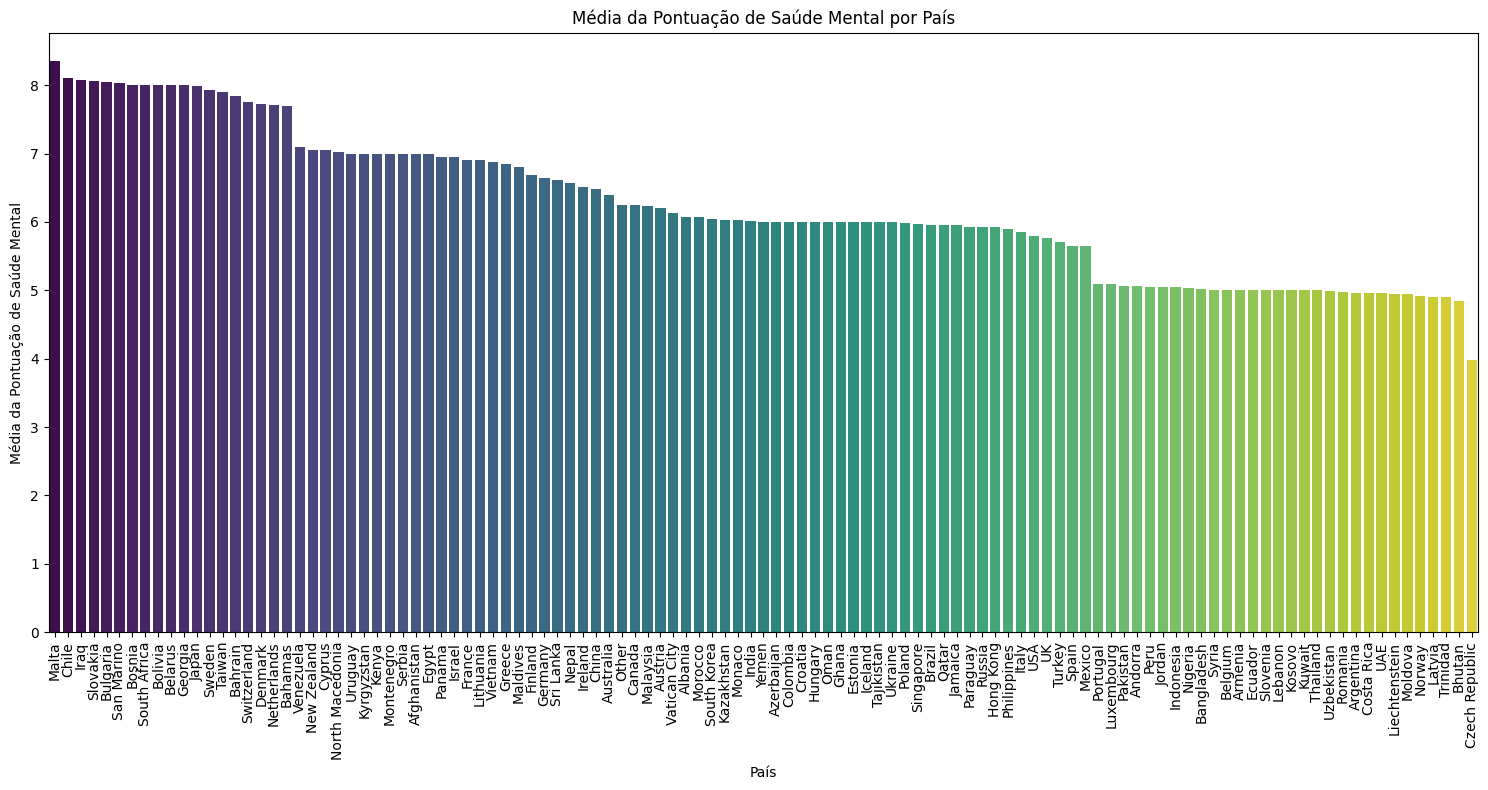

In [436]:
avg_mental_health_by_country = Student_DF.groupby('Country')['Mental_Health_Score'].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(15, 8))
sns.barplot(x='Country', y='Mental_Health_Score', data=avg_mental_health_by_country, palette='viridis')
plt.title('Média da Pontuação de Saúde Mental por País')
plt.xlabel('País')
plt.ylabel('Média da Pontuação de Saúde Mental')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Distribuição das variáveis de Stress e Saude Mental.

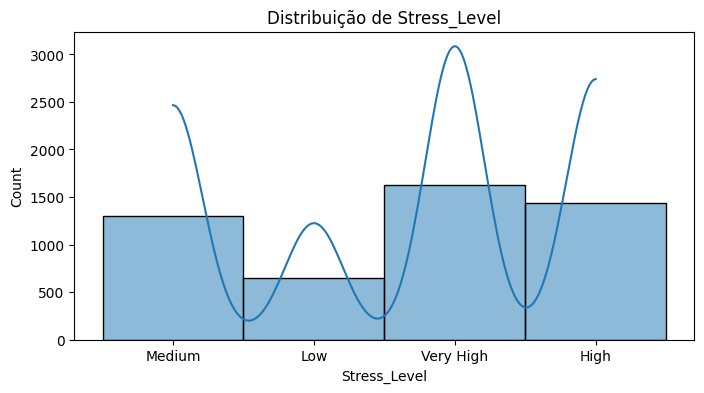

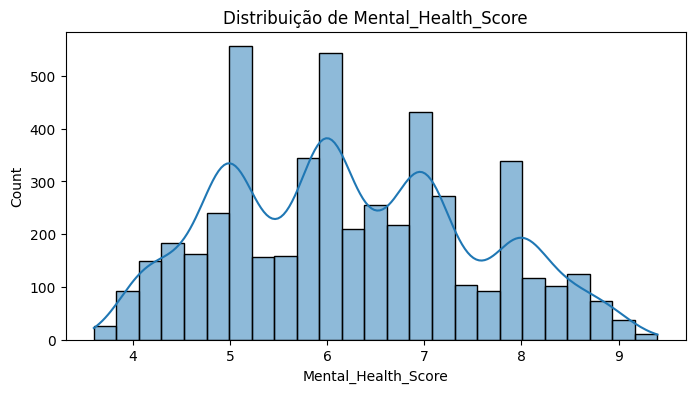

In [437]:
for col in ["Stress_Level", "Mental_Health_Score"]:
    plt.figure(figsize=(8,4))
    sns.histplot(Student_DF[col], kde=True)
    plt.title(f"Distribuição de {col}")
    plt.show()



Relação entre Hábitos e Stress

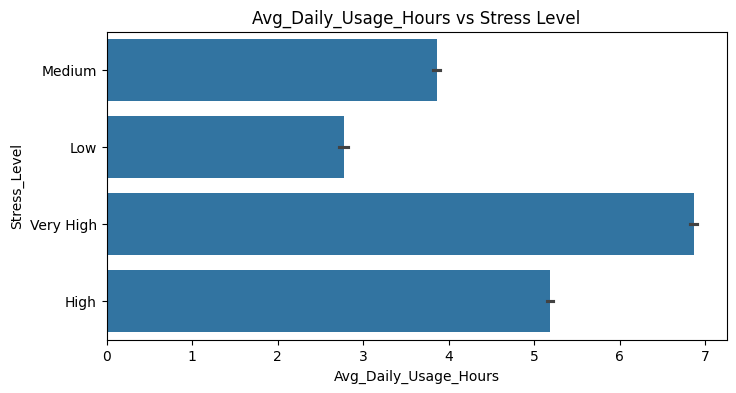

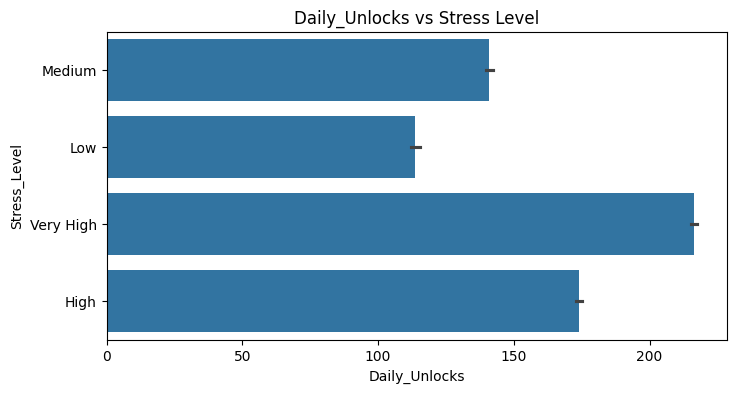

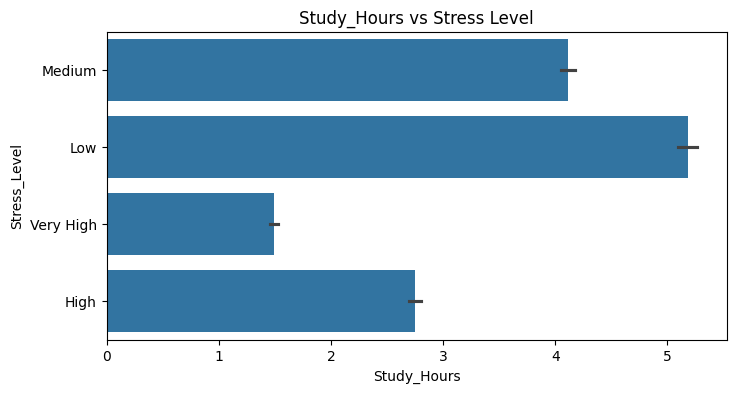

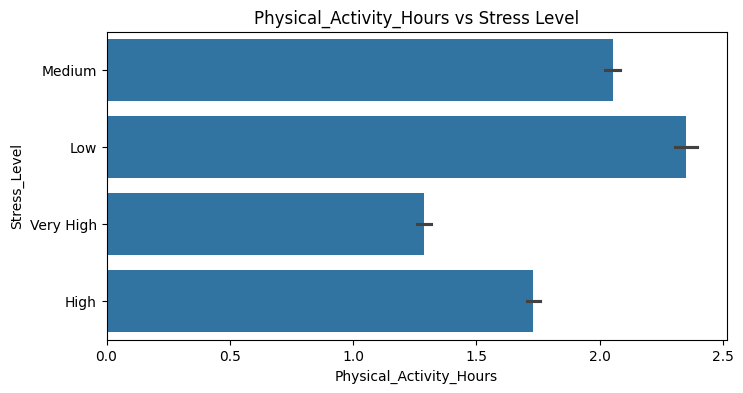

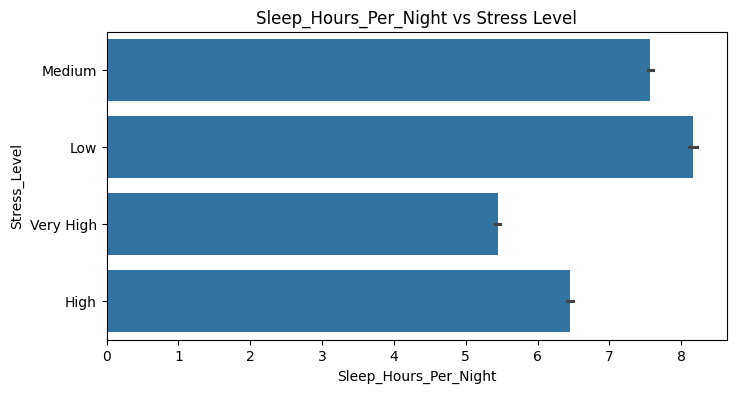

In [438]:
Habits = [
    "Avg_Daily_Usage_Hours", "Daily_Unlocks", "Study_Hours",
    "Physical_Activity_Hours", "Sleep_Hours_Per_Night"
]

for col in Habits:
    plt.figure(figsize=(8,4))
    sns.barplot(x=Student_DF[col], y=Student_DF["Stress_Level"])
    plt.title(f"{col} vs Stress Level")
    plt.show()

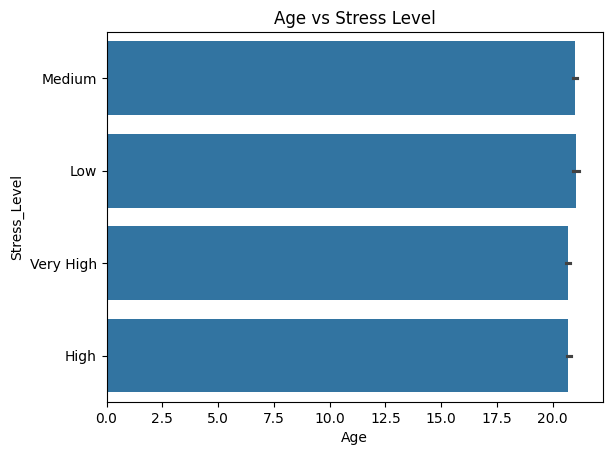

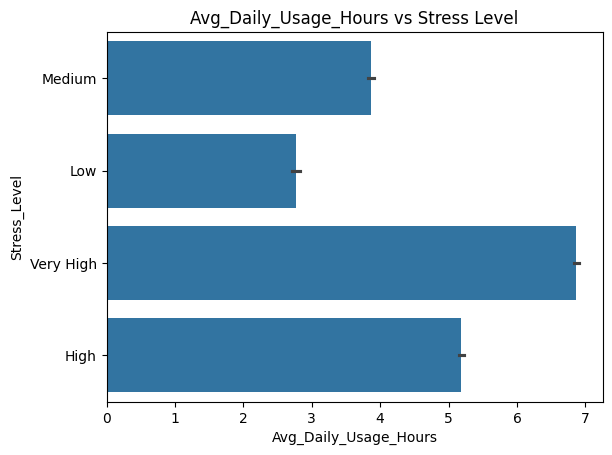

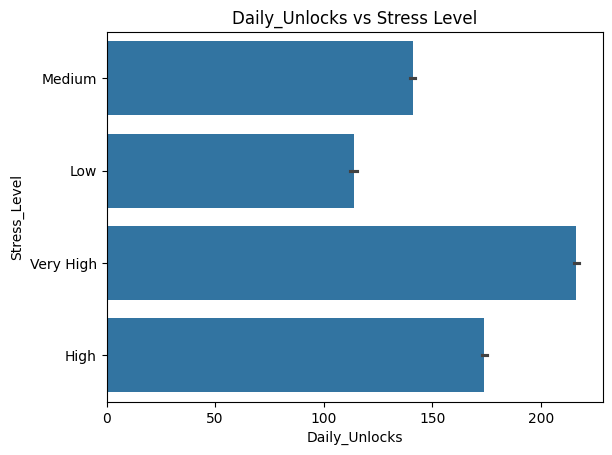

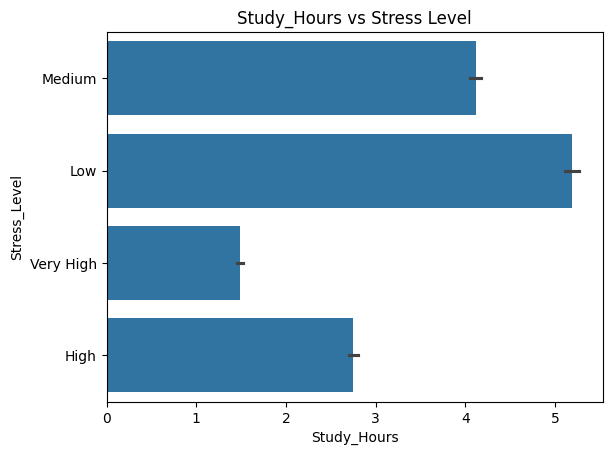

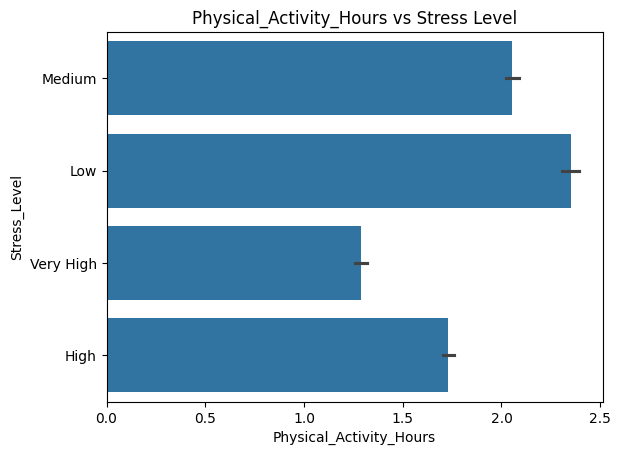

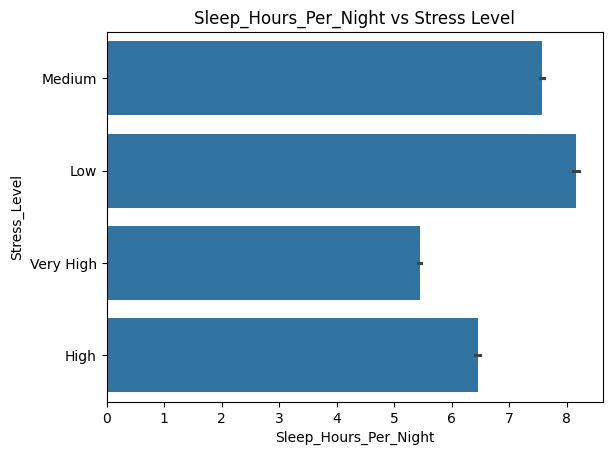

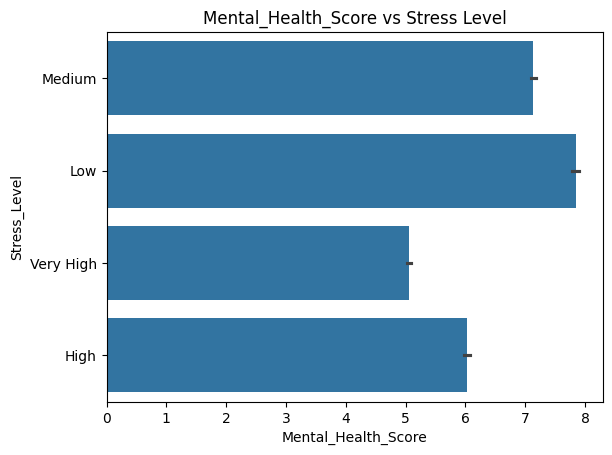

In [439]:
num_cols = Student_DF.select_dtypes(include=['int64','float64']).columns

for col in num_cols:
    if col != "Stress_Level":
        sns.barplot(x=Student_DF[col], y=Student_DF["Stress_Level"])
        plt.title(f"{col} vs Stress Level")
        plt.show()

Relação entre Habitos e Saude Mental.

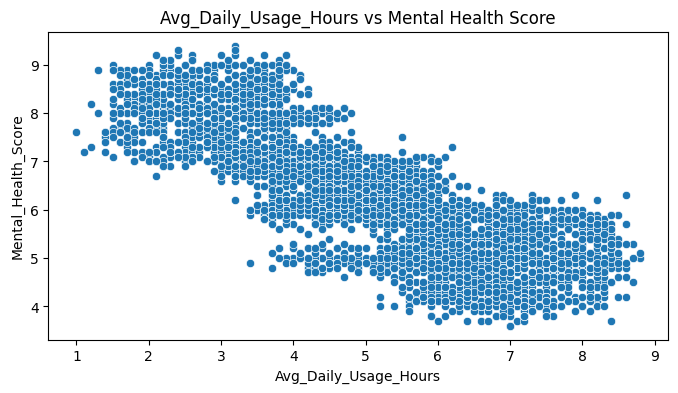

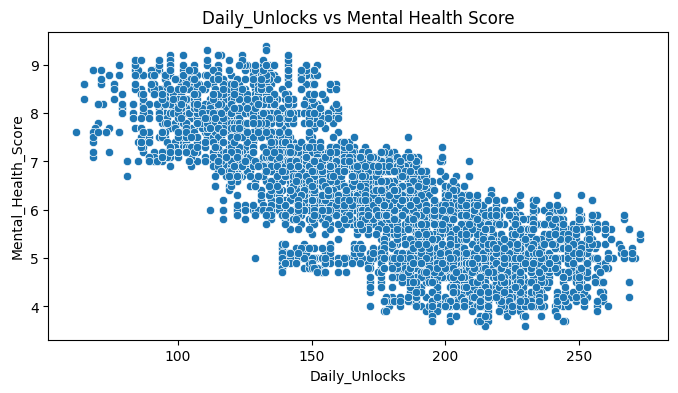

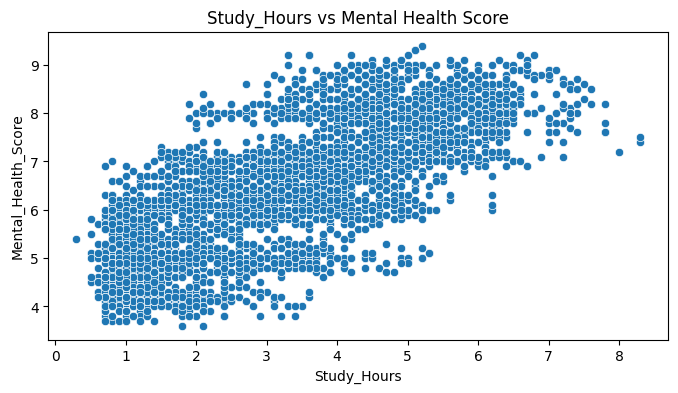

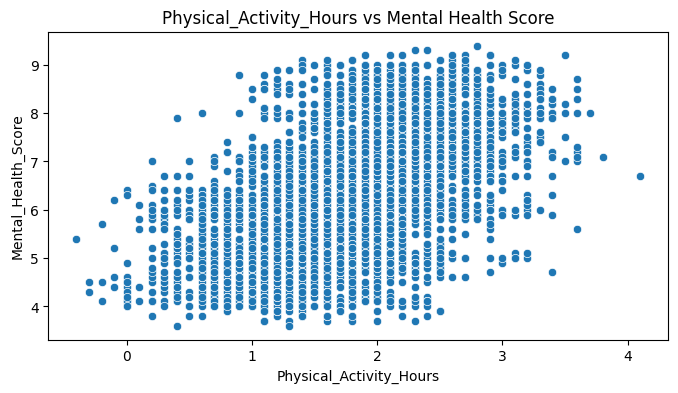

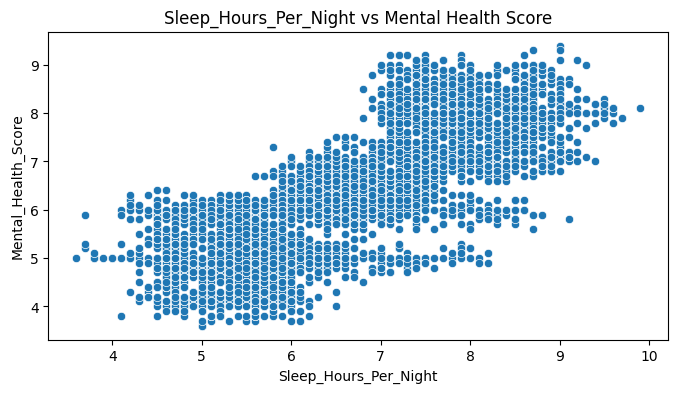

In [440]:
for col in Habits:
    plt.figure(figsize=(8,4))
    sns.scatterplot(x=Student_DF[col], y=Student_DF["Mental_Health_Score"])
    plt.title(f"{col} vs Mental Health Score")
    plt.show()

Categoricas versus Stress e Saude Mental.

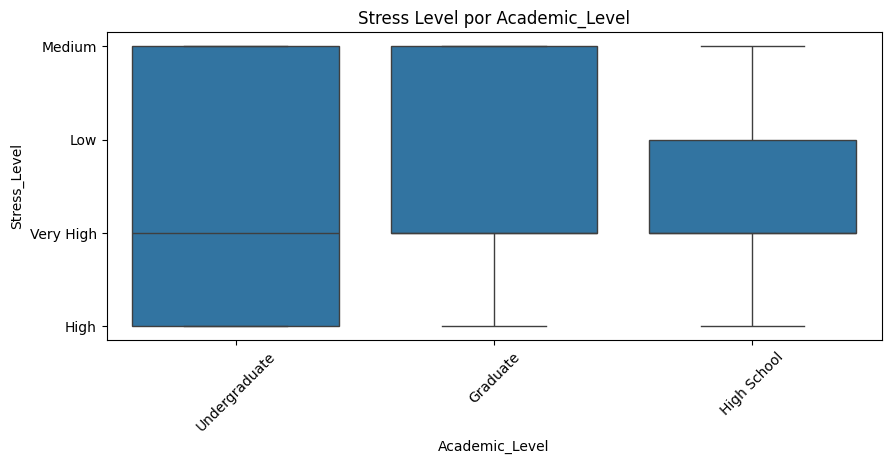

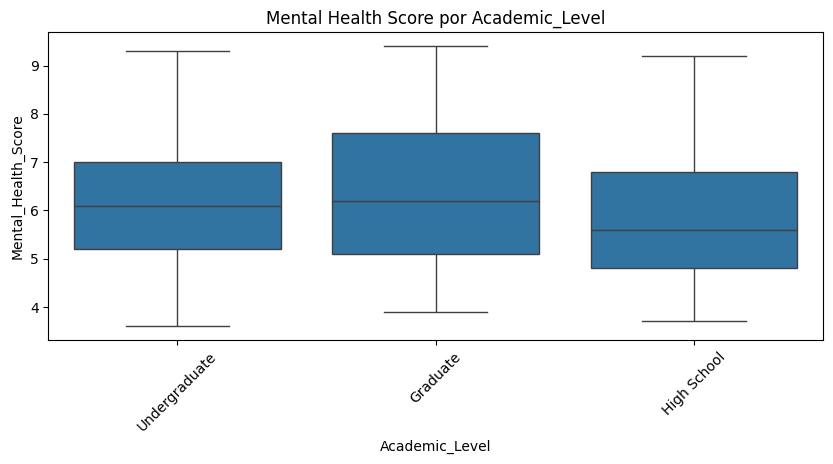

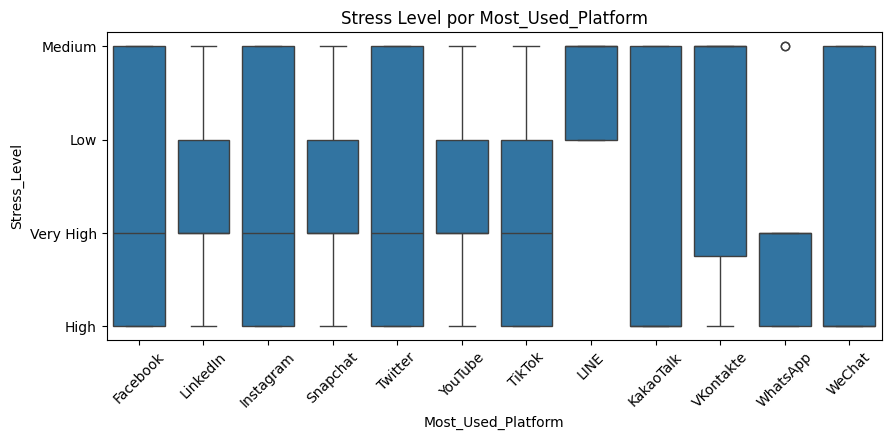

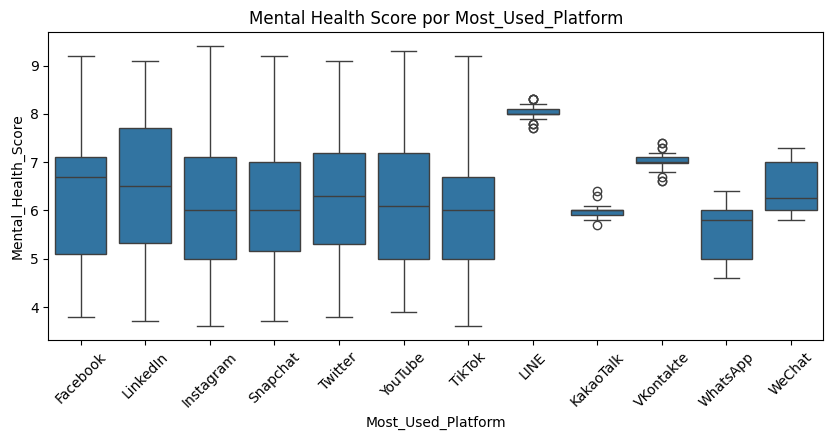

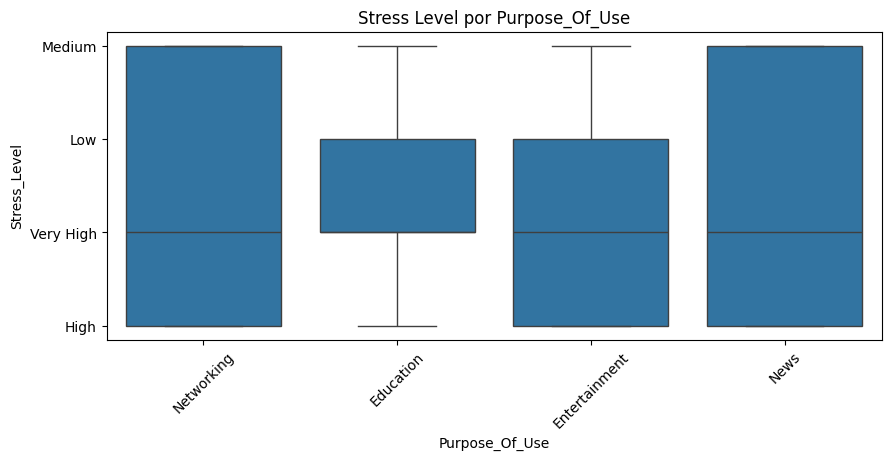

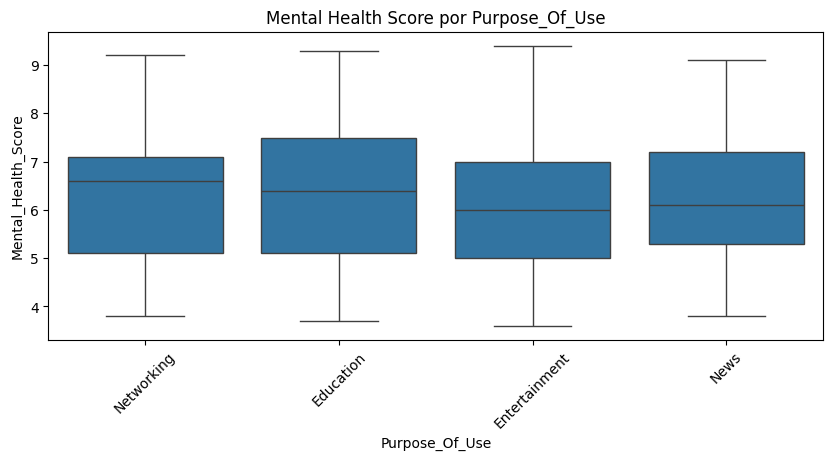

In [441]:
for col in ["Academic_Level", "Most_Used_Platform", "Purpose_Of_Use"]:
    plt.figure(figsize=(10,4))
    sns.boxplot(x=col, y="Stress_Level", data=Student_DF)
    plt.title(f"Stress Level por {col}")
    plt.xticks(rotation=45)
    plt.show()

    plt.figure(figsize=(10,4))
    sns.boxplot(x=col, y="Mental_Health_Score",data=Student_DF)
    plt.title(f"Mental Health Score por {col}")
    plt.xticks(rotation=45)
    plt.show()

,mean,std,count
Stress_Level,,,
Low,7.840747,0.723625,643
Medium,7.135907,0.916431,1295
High,6.026755,0.829129,1439
Very High,5.051326,0.663711,1621


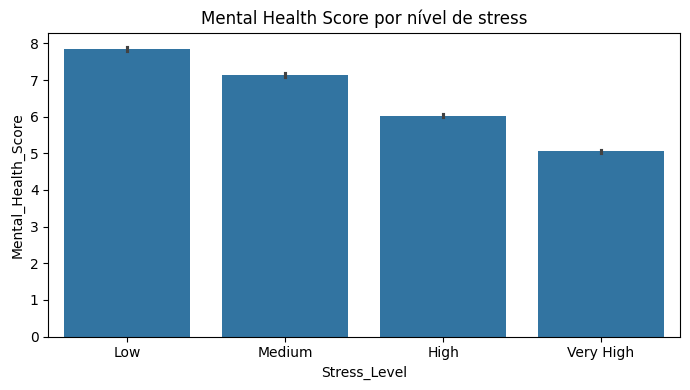

In [442]:
stress_order=["Low","Medium","High","Very High"]
display(Student_DF.groupby("Stress_Level").Mental_Health_Score.agg(["mean","std","count"]).reindex(stress_order))
plt.figure(figsize=(7,4))
sns.barplot(data=Student_DF,x="Stress_Level",y="Mental_Health_Score",order=stress_order,errorbar="ci")
plt.title("Mental Health Score por nível de stress"); plt.tight_layout(); plt.show()

Correlação entre Variaveis Numericas.

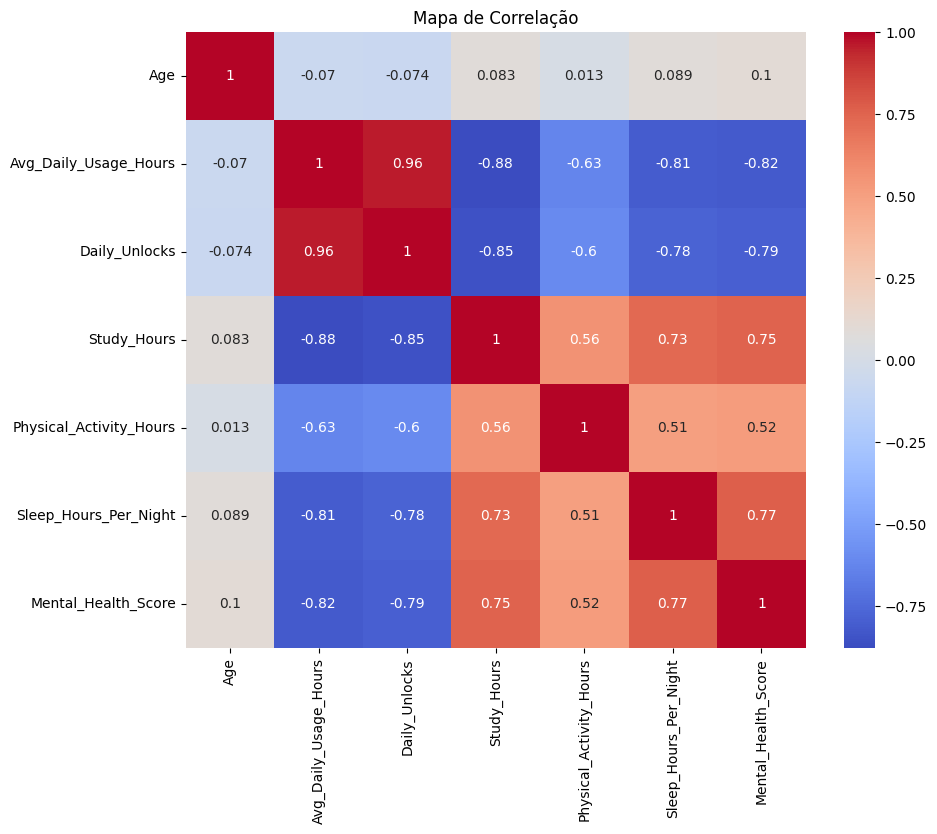

In [443]:
plt.figure(figsize=(10,8))
corr = Student_DF[num_cols].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Mapa de Correlação")
plt.show()

In [444]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Criar uma cópia para não alterar os dados originais brutos de forma irreversível
Student_DF_encoded = Student_DF.copy()

# Mapear a coluna ordinal 'Stress_Level' para valores numéricos
stress_map = {"Low": 0, "Medium": 1, "High": 2, "Very High": 3}
Student_DF_encoded["Stress_Level"] = Student_DF_encoded["Stress_Level"].map(stress_map)

features = [
    "Avg_Daily_Usage_Hours", "Daily_Unlocks", "Study_Hours",
    "Physical_Activity_Hours", "Sleep_Hours_Per_Night",
    "Stress_Level", "Mental_Health_Score"
]

X = Student_DF_encoded[features]

# Normalizar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Criar clusters
kmeans = KMeans(n_clusters=4, random_state=42)
Student_DF["cluster"] = kmeans.fit_predict(X_scaled)

In [445]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_coords = pca.fit_transform(X_scaled)

Student_DF["pca_x"] = pca_coords[:, 0]
Student_DF["pca_y"] = pca_coords[:, 1]

In [446]:
import plotly.express as px

fig_clusters = px.scatter(
    Student_DF,
    x="pca_x",
    y="pca_y",
    color="cluster",
    hover_data=[
        "Academic_Level", "Most_Used_Platform", "Purpose_Of_Use",
        "Stress_Level", "Mental_Health_Score"
    ],
    title="Mapa de Clusters — Stress & Saúde Mental",
    color_continuous_scale="Viridis"
)

fig_clusters.show()

# Descrição dos clusters
"""
Cluster 0: estudantes com muito uso digital + pouco sono → stress alto

Cluster 1: estudantes equilibrados → stress baixo

Cluster 2: muito estudo + pouca atividade física → saúde mental mais frágil

Cluster 3: muito exercício + bom sono → melhor mental_health_score
"""

'\nCluster 0: estudantes com muito uso digital + pouco sono → stress alto\n\nCluster 1: estudantes equilibrados → stress baixo\n\nCluster 2: muito estudo + pouca atividade física → saúde mental mais frágil\n\nCluster 3: muito exercício + bom sono → melhor mental_health_score\n'

In [447]:

Student_DF_encoded["cluster"] = Student_DF["cluster"]
cluster_profiles = Student_DF_encoded.groupby("cluster")[features].mean().round(2)
cluster_profiles

,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
cluster,,,,,,,
0,2.90,116.50,5.17,2.38,8.09,0.47,7.94
1,7.11,223.03,1.28,1.15,5.36,2.95,4.93
2,5.59,184.09,2.36,1.69,6.07,2.24,5.68
3,4.32,151.99,3.60,1.90,7.27,1.34,6.67


In [448]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression,Ridge
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

X=Student_DF.drop(columns="Mental_Health_Score"); y=Student_DF.Mental_Health_Score
cat=X.select_dtypes("object").columns.tolist()
num=X.select_dtypes(exclude="object").columns.tolist()
pre=ColumnTransformer([("num",StandardScaler(),num),("cat",OneHotEncoder(handle_unknown="ignore"),cat)])
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=42)

models={"Linear Regression":LinearRegression(),"Ridge":Ridge(alpha=1),
        "Random Forest":RandomForestRegressor(n_estimators=300,random_state=42,n_jobs=-1),
        "Gradient Boosting":GradientBoostingRegressor(random_state=42)}
results=[]; fitted={}
for name,m in models.items():
    pipe=Pipeline([("preprocessor",pre),("model",m)])
    pipe.fit(X_train,y_train); pred=pipe.predict(X_test); fitted[name]=pipe
    results.append([name,mean_absolute_error(y_test,pred),mean_squared_error(y_test,pred)**.5,r2_score(y_test,pred)])
results_df=pd.DataFrame(results,columns=["Model","MAE","RMSE","R2"]).sort_values("RMSE")
display(results_df)

,Model,MAE,RMSE,R2
0,Linear Regression,0.000024,0.000050,1.000000
1,Ridge,0.014543,0.018553,0.999807
2,Random Forest,0.231423,0.311438,0.945668
3,Gradient Boosting,0.346372,0.444024,0.889560


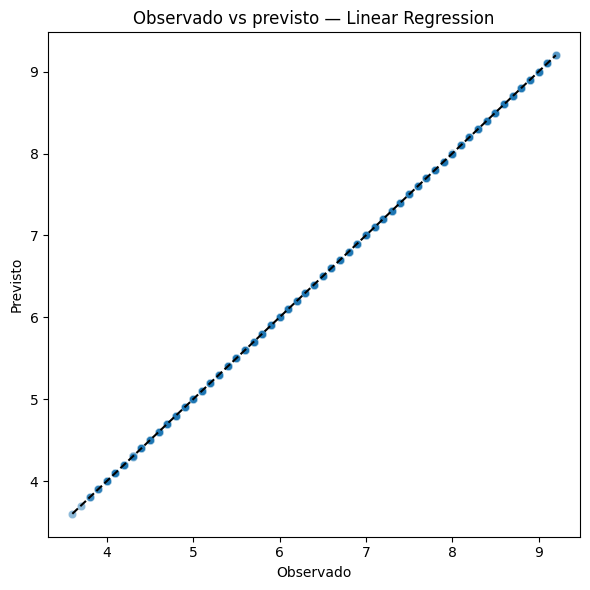

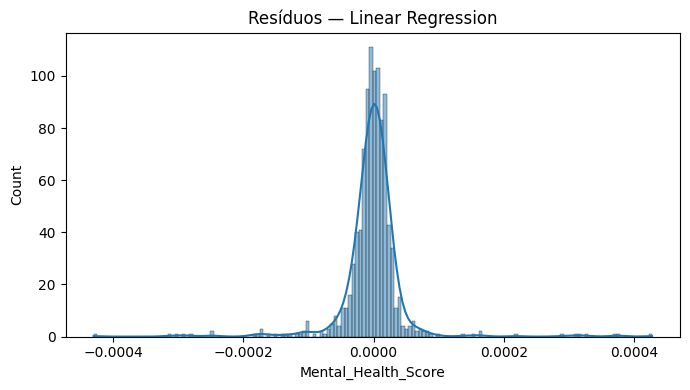

In [449]:
best_name=results_df.iloc[0].Model
pred=fitted[best_name].predict(X_test)
plt.figure(figsize=(6,6)); sns.scatterplot(x=y_test,y=pred,alpha=.5)
lims=[min(y_test.min(),pred.min()),max(y_test.max(),pred.max())]
plt.plot(lims,lims,"k--"); plt.xlabel("Observado"); plt.ylabel("Previsto")
plt.title(f"Observado vs previsto — {best_name}"); plt.tight_layout(); plt.show()

residuals=y_test-pred
plt.figure(figsize=(7,4)); sns.histplot(residuals,kde=True)
plt.title(f"Resíduos — {best_name}"); plt.tight_layout(); plt.show()

In [450]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, r2_score

features = [
    "Avg_Daily_Usage_Hours", "Daily_Unlocks", "Study_Hours",
    "Physical_Activity_Hours", "Sleep_Hours_Per_Night"
]

X = Student_DF[features]

y_stress = Student_DF_encoded["Stress_Level"]
y_mental = Student_DF["Mental_Health_Score"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_scaled, y_stress, test_size=0.2, random_state=42)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_scaled, y_mental, test_size=0.2, random_state=42)

rf_stress = RandomForestRegressor(random_state=42)
rf_stress.fit(X_train_s, y_train_s)
pred_s = rf_stress.predict(X_test_s)

rf_mental = RandomForestRegressor(random_state=42)
rf_mental.fit(X_train_m, y_train_m)
pred_m = rf_mental.predict(X_test_m)

display("Modelo Stress:")
print("RMSE:", root_mean_squared_error(y_test_s, pred_s))
print("R2:", r2_score(y_test_s, pred_s))

display("Modelo Saúde Mental:")
print("RMSE:", root_mean_squared_error(y_test_m, pred_m))
print("R2:", r2_score(y_test_m, pred_m))

'Modelo Stress:'

RMSE: 0.39566134509198647
R2: 0.8603466625036241


'Modelo Saúde Mental:'

RMSE: 0.5730355001725944
R2: 0.8160608427545752
